# Homework 4

## Question

In Homework 3, we searched over many choices of slope and intercept to find a line of best fit.  Here we'll use scikit-learn to find the line, and investigate what happens when we add an outlier.

* Import NumPy as `np`, pandas as `pd`, and `matplotlib.pyplot` as `plt`.
* Define the following data.  Read through the code and try to understand all pieces of it.

```python
rng = np.random.default_rng(210)
x = np.linspace(1, 5, 20)
y = 2*x + 1 + rng.normal(loc=0, scale=0.8, size=len(x))
```

* Plot the data.
* Put these values into a pandas DataFrame named `df`, with columns named `"x"` and `"y"`.
* Display the type and shape of both `df["x"]` and `df[["x"]]`.  Which of these should we use as the input features when fitting a scikit-learn model?  Answer in a markdown cell.

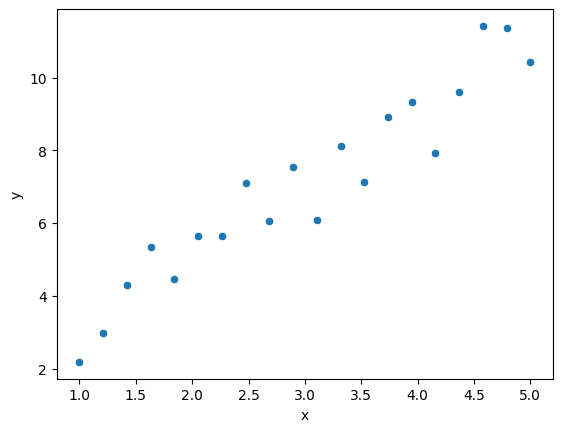

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(210)
x = np.linspace(1, 5, 20)
y = 2*x + 1 + rng.normal(loc=0, scale=0.8, size=len(x))

fig, ax = plt.subplots()
ax.scatter(x, y)
ax.set_xlabel("x")
ax.set_ylabel("y")

We should use df[["x"]]. sk learn expects the input features to be 2 deminseional (rows by columns) and df[["x"]] is a dataFrame of shape (20, 1), while df["x"] is a 1 dim series.

## Question

* Using `LinearRegression` from scikit-learn,  fit a `LinearRegression` object using the `"x"` column of `df` as the only input feature and the `"y"` column as the target.
* Display the `coef_` and `intercept_` attributes.  Report the equation of the fitted line in a markdown cell.  How close are its slope and intercept to the values used to generate the data?

* Create a NumPy array `arr_plot` of 100 evenly spaced coordinates from 1 to 5.
* Use the `predict` method of your LinearRegression object to make predictions for `arr_plot`.
* Make the analogous predictions directly from the fitted coefficient and intercept.
* Check that the two sets of predictions are close by making sure that the absolute values of their coordinates differ by less than $10^{-6}$.  (Use the NumPy function `abs` and the `all` method.)
* Perform a similar check using the special NumPy function `allclose`.

In [4]:
from sklearn.linear_model import LinearRegression

reg_clean = LinearRegression()
reg_clean.fit(df[["x"]], df["y"])

print(reg_clean.coef_, reg_clean.intercept_)

[2.0022633] 1.0682181273493727


The fitted line is y = 2.002x + 1.068.

In [7]:
arr_plot = np.linspace(1, 5, 100)

pred1 = reg_clean.predict(pd.DataFrame({"x": arr_plot}))
pred2 = reg_clean.coef_[0]*arr_plot + reg_clean.intercept_

(np.abs(pred1 - pred2) < 10**-6).all()
np.allclose(pred1, pred2)

True

## Question

Here we'll add one point that is far above the other points.  We want to keep the original data so that we can compare our results.

* Make a copy of `df` named `df_outlier`, using the `copy` method.
* Add a row corresponding to the point `(4, 40)`.  One option is to use `pd.concat`.  Another option is to use `df_outlier.iloc`.  One option is to use `df_outlier.loc[len(df_outlier)] = [4, 40]`.  Put the copying and row addition in the same code cell, so that running that cell again still gives just one added point.
* Check that `df` still has 20 rows and `df_outlier` has 21 rows.
* Instantiate a new `LinearRegression` object named `reg_mse` and fit it using the new outlier DataFrame.
* Add a column to `df_outlier` named `"pred_mse"`, containing this new model's predictions for `df_outlier[["x"]]`.  We call it `mse` because it is fit by minimizing the Mean Squared Error.
* Report the new fitted equation in a markdown cell.  How did the slope and intercept change compared with `reg_clean`?

In [8]:
df_outlier = df.copy()
df_outlier.loc[len(df_outlier)] = [4, 40]

In [9]:
len(df), len(df_outlier)

(20, 21)

In [10]:
reg_mse = LinearRegression()
reg_mse.fit(df_outlier[["x"]], df_outlier["y"])

df_outlier["pred_mse"] = reg_mse.predict(df_outlier[["x"]])

print(reg_mse.coef_, reg_mse.intercept_)

[2.97019056] -0.4091445276723391


The new line is y = 2.970x - 0.409. Compared with reg_clean, the slope went up by almost 1 and the intercept dropped by about 1.5.

## Question

`LinearRegression` chooses its slope and intercept to minimize MSE on the data it is fitted to.  To find a line that minimizes Mean Absolute Error MAE instead, we can use the following object.  You do not need to understand these keyword arguments; the important thing is to notice the similarity to the `LinearRegression` syntax, and to understand that this is solving a different minimization problem.

```python
from sklearn.linear_model import QuantileRegressor

reg_mae = QuantileRegressor(quantile=0.5, alpha=0, solver="highs")
```

* Fit `reg_mae` using the same input feature and target from `df_outlier` as in the previous question.
* Add a column to `df_outlier` named `"pred_mae"`, containing this model's predictions for `df_outlier[["x"]]`.
* Report the fitted equation in a markdown cell.

* Using Matplotlib, on the same axes, make a scatterplot of the data in `df_outlier` and plot three fitted lines: `reg_clean` in blue, `reg_mse` in red, and `reg_mae` in black.  For each line, use `arr_plot` for the $x$ coordinates and the model's corresponding predictions for $y$ coordinates.
* Use the `label` keyword argument to distinguish the lines, and display a legend using `ax.legend()`.  Include axis labels.
* Which of the two models fitted to `df_outlier` appears more influenced by the outlier?  Answer in a markdown cell.

In [11]:
from sklearn.linear_model import QuantileRegressor

reg_mae = QuantileRegressor(quantile=0.5, alpha=0, solver="highs")
reg_mae.fit(df_outlier[["x"]], df_outlier["y"])

df_outlier["pred_mae"] = reg_mae.predict(df_outlier[["x"]])

print(reg_mae.coef_, reg_mae.intercept_)

[2.21141623] 0.6406653018572177


The MAE line is y = 2.211x + 0.641

<Axes: xlabel='x', ylabel='y'>

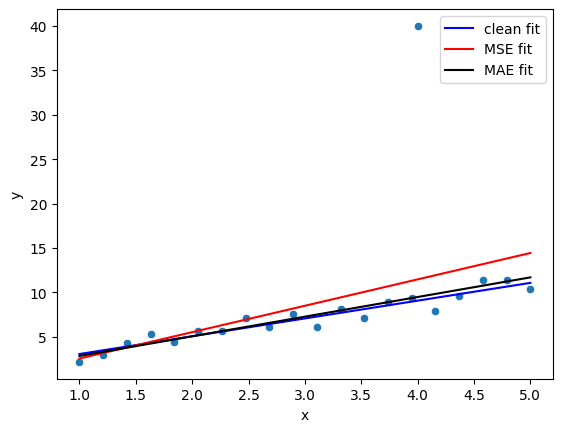

In [13]:
df_outlier["pred_clean"] = reg_clean.predict(df_outlier[["x"]])

sns.scatterplot(x = "x",
                y = "y",
                data = df_outlier
                )
sns.lineplot(x = "x",
             y = "pred_clean",
             data = df_outlier,
             color = "blue",
             label = "clean fit"
             )
sns.lineplot(x = "x",
             y = "pred_mse",
             data = df_outlier,
             color = "red",
             label = "MSE fit"
             )
sns.lineplot(x = "x",
             y = "pred_mae",
             data = df_outlier,
             color = "black",
             label = "MAE fit"
             )

## Submission

* When you've completed this assignment, save your work, commit and push your changes to GitHub (including this notebook and any changes to `requirements.txt`), and share the GitHub directory through Gradescope, linked from the left side of Canvas.